# 06 - Model Comparison & Evaluation

## Objective
Compare the predictive performance of the Multilayer Perceptron (MLP) and Multiple Linear Regression (MLR) models using identical Repeated 5-Fold Cross-Validation splits (SOP 5).

### Key Evaluation Metrics:
- **RMSE** (Root Mean Squared Error): Lower is better
- **MAE** (Mean Absolute Error): Lower is better
- **R²** (Coefficient of Determination): Higher is better

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Paths setup
cwd = Path.cwd()
project_candidates = [cwd, cwd.parent]
PROJECT_ROOT = next(
    (path for path in project_candidates if (path / "requirements.txt").is_file()),
    cwd,
)

DATA_DIR = PROJECT_ROOT / "data"
RESULTS_DIR = PROJECT_ROOT / "results"
TABLES_DIR = RESULTS_DIR / "tables"
GRAPHS_DIR = RESULTS_DIR / "graphs"

TABLES_DIR.mkdir(parents=True, exist_ok=True)
GRAPHS_DIR.mkdir(parents=True, exist_ok=True)

INPUT_PATH = DATA_DIR / "scored_data.csv"
print(f"Project root: {PROJECT_ROOT}")
print(f"Scored data path: {INPUT_PATH}")
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RepeatedKFold, cross_validate


Project root: c:\Users\julie\Downloads\IS_Research\ai-adoption-analysis
Scored data path: c:\Users\julie\Downloads\IS_Research\ai-adoption-analysis\data\scored_data.csv


## Load Scored Dataset

In [2]:
if not INPUT_PATH.is_file():
    raise FileNotFoundError(
        f"Scored dataset not found at {INPUT_PATH}. Please run 02_scoring.ipynb first."
    )

df = pd.read_csv(INPUT_PATH)
print(f"Loaded {len(df)} respondents.")

feature_cols = [
    "ai_familiarity_score",
    "perceived_usefulness_score",
    "perceived_ease_of_use_score",
    "trust_score",
    "accessibility_score",
    "digital_literacy_score",
]
target_col = "ai_adoption_score"

X = df[feature_cols].copy()
y = df[target_col].copy()

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")
display(X.head())


Loaded 100 respondents.
Features shape: (100, 6)
Target shape: (100,)


,ai_familiarity_score,perceived_usefulness_score,perceived_ease_of_use_score,trust_score,accessibility_score,digital_literacy_score
0,3.666667,4.000000,3.333333,2.333333,3.333333,4.333333
1,5.000000,5.000000,5.000000,3.666667,3.666667,4.666667
2,4.000000,4.000000,4.000000,3.333333,4.333333,3.666667
3,4.333333,2.333333,4.000000,1.000000,3.666667,3.333333
4,4.333333,4.666667,4.000000,3.666667,3.333333,4.000000


## Benchmark Comparison under Identical CV Splits

Both models are evaluated on identical CV folds to guarantee a fair comparison.

In [3]:
rkf = RepeatedKFold(n_splits=5, n_repeats=10, random_state=42)

mlp_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPRegressor(
        hidden_layer_sizes=(16, 8),
        activation="relu",
        solver="adam",
        alpha=0.01,
        max_iter=1000,
        random_state=42,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=20
    ))
])

mlr_pipe = Pipeline([
    ("mlr", LinearRegression())
])

scoring = {
    "neg_rmse": "neg_root_mean_squared_error",
    "neg_mae": "neg_mean_absolute_error",
    "r2": "r2",
}

mlp_cv = cross_validate(mlp_pipe, X, y, cv=rkf, scoring=scoring)
mlr_cv = cross_validate(mlr_pipe, X, y, cv=rkf, scoring=scoring)

comparison_df = pd.DataFrame([
    {
        "Model": "Multilayer Perceptron (MLP)",
        "RMSE (Mean)": -mlp_cv["test_neg_rmse"].mean(),
        "RMSE (Std)": mlp_cv["test_neg_rmse"].std(),
        "MAE (Mean)": -mlp_cv["test_neg_mae"].mean(),
        "MAE (Std)": mlp_cv["test_neg_mae"].std(),
        "R2 (Mean)": mlp_cv["test_r2"].mean(),
        "R2 (Std)": mlp_cv["test_r2"].std(),
    },
    {
        "Model": "Multiple Linear Regression (MLR)",
        "RMSE (Mean)": -mlr_cv["test_neg_rmse"].mean(),
        "RMSE (Std)": mlr_cv["test_neg_rmse"].std(),
        "MAE (Mean)": -mlr_cv["test_neg_mae"].mean(),
        "MAE (Std)": mlr_cv["test_neg_mae"].std(),
        "R2 (Mean)": mlr_cv["test_r2"].mean(),
        "R2 (Std)": mlr_cv["test_r2"].std(),
    }
])

display(comparison_df)

comparison_path = TABLES_DIR / "model_comparison.csv"
comparison_df.to_csv(comparison_path, index=False)
print(f"Comparison summary saved to: {comparison_path}")

c:\Users\julie\Downloads\IS_Research\ai-adoption-analysis\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


,Model,RMSE (Mean),RMSE (Std),MAE (Mean),MAE (Std),R2 (Mean),R2 (Std)
0,Multilayer Perceptron (MLP),0.951581,0.178756,0.764469,0.148863,-0.291195,0.541338
1,Multiple Linear Regression (MLR),0.854553,0.154297,0.658411,0.097754,-0.052573,0.523378


Comparison summary saved to: c:\Users\julie\Downloads\IS_Research\ai-adoption-analysis\results\tables\model_comparison.csv


## Visualization of Comparison Metrics

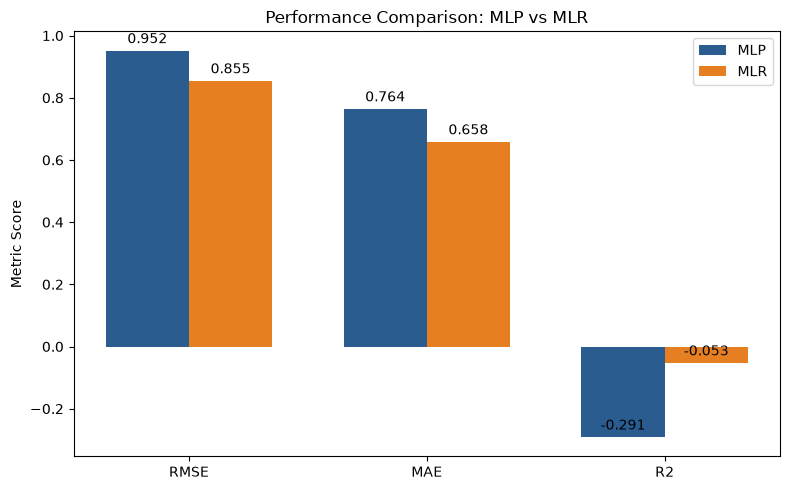

Comparison graph saved to: c:\Users\julie\Downloads\IS_Research\ai-adoption-analysis\results\graphs\model_comparison.png


In [4]:
metrics = ["RMSE", "MAE", "R2"]
mlp_vals = [
    -mlp_cv["test_neg_rmse"].mean(),
    -mlp_cv["test_neg_mae"].mean(),
    mlp_cv["test_r2"].mean(),
]
mlr_vals = [
    -mlr_cv["test_neg_rmse"].mean(),
    -mlr_cv["test_neg_mae"].mean(),
    mlr_cv["test_r2"].mean(),
]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
rects1 = ax.bar(x - width/2, mlp_vals, width, label="MLP", color="#2b5c8f")
rects2 = ax.bar(x + width/2, mlr_vals, width, label="MLR", color="#e67e22")

ax.set_ylabel("Metric Score")
ax.set_title("Performance Comparison: MLP vs MLR")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend()

for rect in rects1 + rects2:
    height = rect.get_height()
    ax.annotate(f"{height:.3f}",
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3),
                textcoords="offset points",
                ha="center", va="bottom")

plt.tight_layout()
comparison_graph_path = GRAPHS_DIR / "model_comparison.png"
plt.savefig(comparison_graph_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()
print(f"Comparison graph saved to: {comparison_graph_path}")